# CME detector on LASCO images, path (ii) (not built)

**The question:** does a learned CME detector, whose outputs feed the hybrid, do better than the
raw coronagraph features of path (i) (`coronagraph_features.ipynb`)?

**The detector** (`models.cme_detector`):
- **stage A:** per C2 image, P(a CME of width ≥ 270° began in the last 3 h), from sorted
  (position-angle-free) sector brightenings; trained on the CDAW catalogue;
- **stage B:** per t0, P(a CME starts at L1 in the next 0–24, 24–48, 48–72 h), from stage A's
  maxima and GOES flares in day bins 0–4 days back; trained on the CMEs found in the ACE data;
- **constraints:** every input of both stages is monotone increasing;
- **cross-fitting:** probabilities are cross-fitted by year, so nothing trains on in-sample outputs.

**The test** (`python -m training.cme_detector`): the outputs are added to the hybrid's 30 regressors.
Six yearly walk-forward folds (2019-10 → 2025-10); score: per-run mean TIMSE / persistence,
geometric mean over folds; also on CME runs and the rest. The eval year is not used.

**Keep rule (set before running):** more than 1% better, winning at least 4 of 6 folds, CME runs
better, and the other runs not worse by more than 0.5%.

1. Scores
2. By fold
3. The stages fold by fold
4. CME runs and the rest
5. Findings

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from training import cme_detector as cm

df = pd.read_csv(cm.EXPERIMENTS / "cme_detector.csv").set_index("fold")
ref = "hybrid shipped"
names = cm.variant_names()[1:]


def geo(c):
    return float(np.exp(np.log(df[c]).mean()))


rows = {n: {"score": geo(n), "vs shipped": geo(n) / geo(ref) - 1,
            "folds won": int((df[n] < df[ref]).sum()),
            "CME runs": geo(f"{n} cme") - 1, "other runs": geo(f"{n} other") - 1} for n in names}
rows[ref] = {"score": geo(ref)}
summary = pd.DataFrame(rows).T.sort_values("score")
summary["keep"] = ((summary["vs shipped"] < -0.01) & (summary["folds won"] >= 4)
                   & (summary["CME runs"] < 0) & (summary["other runs"] < 0.005))
with pd.option_context("display.float_format", "{:.4f}".format):
    display(summary)

,score,vs shipped,folds won,CME runs,other runs,keep
hybrid + both,0.4181,-0.0021,3.0000,-0.0213,0.0114,False
hybrid + arrival,0.4187,-0.0008,2.0000,-0.0103,0.0031,False
hybrid shipped,0.4190,NaN,NaN,NaN,NaN,False
hybrid + detector,0.4197,0.0018,3.0000,-0.0162,0.0153,False


## 2. By fold (% change against the shipped hybrid)

fold,2019-10,2020-10,2021-10,2022-10,2023-10,2024-10
arrival,-1.16,0.22,0.04,0.30,-0.69,0.81
detector,-0.09,0.91,-0.50,0.67,-2.28,2.43
both,-1.20,0.44,-0.34,0.58,-2.02,1.29


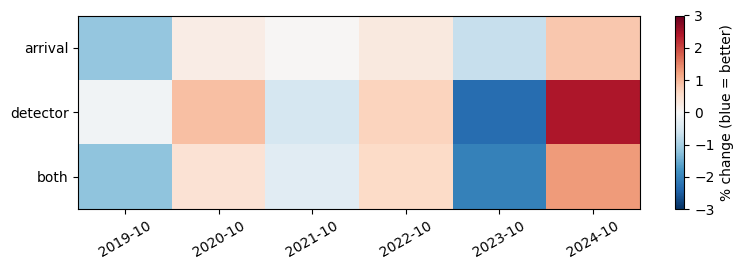

In [2]:
change = pd.DataFrame({n.removeprefix("hybrid + "): 100 * (df[n] / df[ref] - 1) for n in names})
fig, ax = plt.subplots(figsize=(8, 2.8))
im = ax.imshow(change.T.to_numpy(), cmap="RdBu_r", vmin=-3, vmax=3, aspect="auto")
ax.set_yticks(range(change.shape[1]), change.columns)
ax.set_xticks(range(change.shape[0]), change.index, rotation=30)
plt.colorbar(im, label="% change (blue = better)")
plt.tight_layout()
display(change.T.round(2))

## 3. The stages fold by fold (AUC on the fold's own images and t0s; 0.5 = chance)

,stage B cme_l1_0_24h,stage B cme_l1_24_48h,stage B cme_l1_48_72h,stage A
fold,,,,
2019-10,0.324,0.439,0.517,NaN
2020-10,0.631,0.619,0.585,0.794
2021-10,0.491,0.488,0.503,0.732
2022-10,0.589,0.572,0.490,0.802
2023-10,0.641,0.639,0.576,0.803
2024-10,0.591,0.585,0.531,0.828


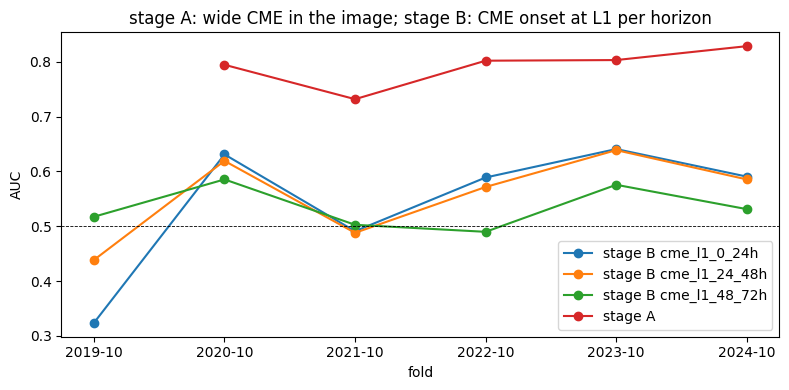

In [3]:
auc = df[[c for c in df.columns if "AUC" in c]].rename(columns=lambda c: c.replace(" AUC", ""))
ax = auc.plot(marker="o", figsize=(8, 4))
ax.axhline(0.5, color="k", lw=0.6, ls="--")
ax.set_ylabel("AUC")
ax.set_title("stage A: wide CME in the image; stage B: CME onset at L1 per horizon")
plt.tight_layout()
display(auc.round(3))

## 4. CME runs and the rest (% change against the shipped hybrid, per fold)

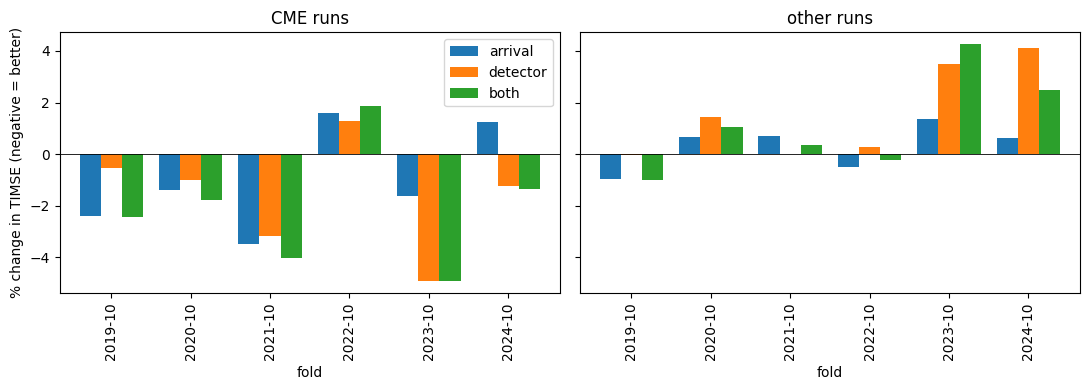

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, part in zip(axes, ("cme", "other"), strict=True):
    tab = pd.DataFrame({n.removeprefix("hybrid + "): 100 * (df[f"{n} {part}"] - 1) for n in names})
    tab.plot.bar(ax=ax, width=0.8, legend=part == "cme")
    ax.axhline(0, color="k", lw=0.6)
    ax.set_title(f"{'CME' if part == 'cme' else 'other'} runs")
    ax.set_ylabel("% change in TIMSE (negative = better)")
plt.tight_layout()

## 5. Findings

- **Not built: nothing passes the bar.** The best set (stage A and B outputs together) gains 0.21% in 3 of 6 folds, against a bar of 1% and 4 of 6.
- **Stage A works:** AUC about 0.80 for wide CMEs on unseen years, with the position-angle-free, monotone inputs.
- **Stage B doesn't:** P(CME at L1 in the next 24 h) reaches AUC 0.64 at best, about 0.5 in 2021-10, and 0.32 in 2019-10, a solar-minimum fold with no wide CME at all. The browse images don't tell an Earth-directed CME from a far-side one, a coincident flare doesn't settle it, and 117 L1 onsets in nine years are too few to learn it.
- **The path (i) trade-off remains, smaller:** CME runs gain 1–2%, the other runs lose 0.3–1.5%.
- **The coronagraph route closes:** neither path passes, so the drag-based arrival model isn't built ([docs/cme_detector.md](../../docs/cme_detector.md)).